In [ ]:
# Cell 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
# Cell 2: Load and inspect the data
def load_data(path):
    return pd.read_csv(path)

def check_data(df):
    print("Shape:", df.shape)
    print("Duplicate rows:", df.duplicated().sum())
    print("Numeric cols:", df.select_dtypes(include="number").shape[1],
          "| Text cols:", df.select_dtypes(exclude="number").shape[1])
    miss = df.isnull().sum()
    print("\nMissing values per column:")
    print(miss[miss > 0].to_string())

def iqr_outliers(df, col):
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    return int(mask.sum())

raw = load_data("titanic.csv")
check_data(raw)
print("\nFare outliers (IQR rule):", iqr_outliers(raw, "Fare"))
print("Age outliers (IQR rule):", iqr_outliers(raw, "Age"))
print("\nSurvival counts (0 = died, 1 = survived):")
print(raw["Survived"].value_counts().to_string())
raw.head()

Shape: (891, 12)
Duplicate rows: 0
Numeric cols: 7 | Text cols: 5

Missing values per column:
Age         177
Cabin       687
Embarked      2

Fare outliers (IQR rule): 116
Age outliers (IQR rule): 11

Survival counts (0 = died, 1 = survived):
Survived
0    549
1    342


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


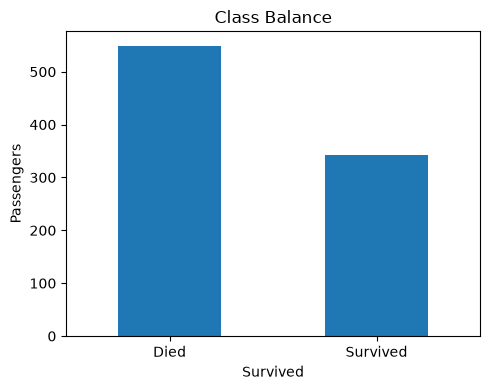

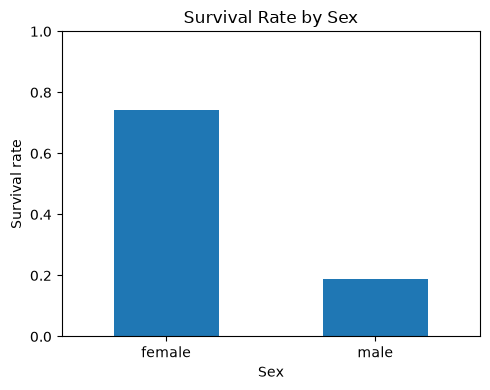

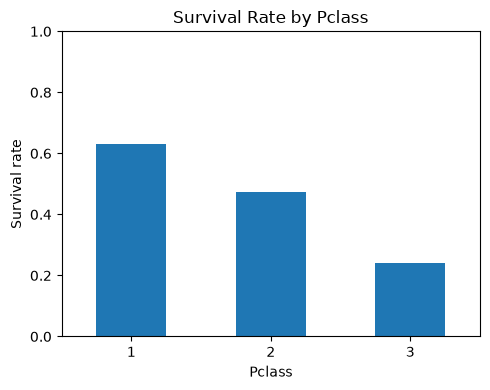

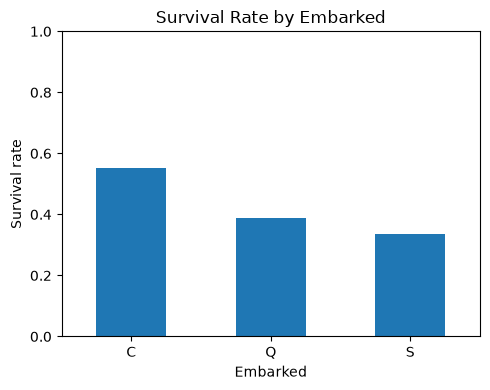

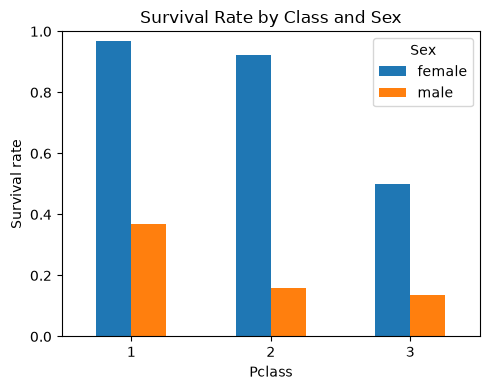

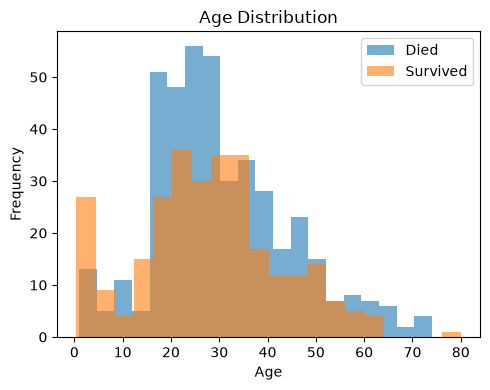

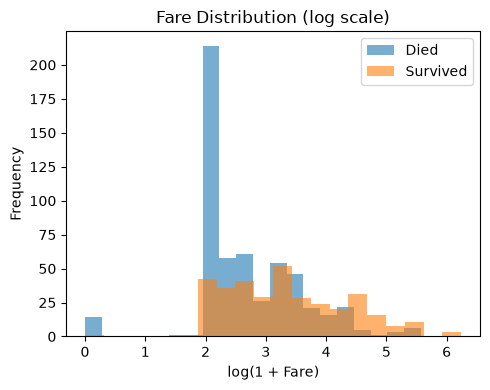

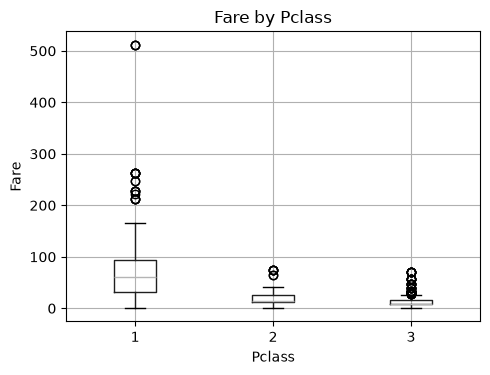

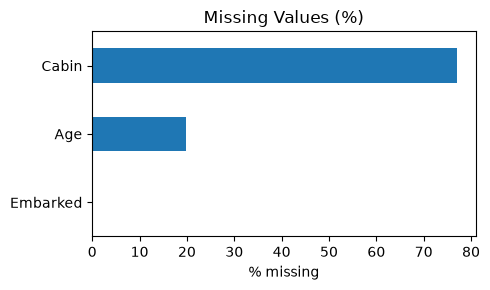

In [3]:
# Cell 3: Data visualization plots
def visualize_data(df):
    # 1. Class balance
    df["Survived"].value_counts().sort_index().rename({0: "Died", 1: "Survived"}).plot(
        kind="bar", rot=0, title="Class Balance", figsize=(5, 4))
    plt.ylabel("Passengers")
    plt.tight_layout()
    plt.show()

    # 2. Survival rate by category
    for col in ["Sex", "Pclass", "Embarked"]:
        df.groupby(col)["Survived"].mean().plot(
            kind="bar", rot=0, ylim=(0, 1), title="Survival Rate by " + col, figsize=(5, 4))
        plt.ylabel("Survival rate")
        plt.tight_layout()
        plt.show()

    # 3. Sex and class together
    df.pivot_table(index="Pclass", columns="Sex", values="Survived").plot(
        kind="bar", rot=0, ylim=(0, 1), title="Survival Rate by Class and Sex", figsize=(5, 4))
    plt.ylabel("Survival rate")
    plt.tight_layout()
    plt.show()

    # 4. Age distribution, split by outcome
    df.groupby("Survived")["Age"].plot(kind="hist", bins=20, alpha=0.6, figsize=(5, 4),
                                       title="Age Distribution")
    plt.legend(["Died", "Survived"])
    plt.xlabel("Age")
    plt.tight_layout()
    plt.show()

    # 5. Fare distribution on a log scale, split by outcome
    d = df.assign(LogFare=np.log1p(df["Fare"]))
    d.groupby("Survived")["LogFare"].plot(kind="hist", bins=20, alpha=0.6, figsize=(5, 4),
                                          title="Fare Distribution (log scale)")
    plt.legend(["Died", "Survived"])
    plt.xlabel("log(1 + Fare)")
    plt.tight_layout()
    plt.show()

    # 6. Fare by class (outliers)
    df.boxplot(column="Fare", by="Pclass", figsize=(5, 4))
    plt.title("Fare by Pclass")
    plt.suptitle("")
    plt.ylabel("Fare")
    plt.tight_layout()
    plt.show()

    # 7. Missing values
    miss = df.isnull().mean().mul(100)
    miss[miss > 0].sort_values().plot(kind="barh", title="Missing Values (%)", figsize=(5, 3))
    plt.xlabel("% missing")
    plt.tight_layout()
    plt.show()

visualize_data(raw)

In [ ]:
# Cell 4: Stratified train/test split
def split_data(df, target="Survived", test_size=0.2, seed=12):
    np.random.seed(seed)
    test_idx = []
    for cls in df[target].unique():                        
        idx = np.where(df[target].values == cls)[0]        
        idx = np.random.permutation(idx)                   
        n_test = int(round(len(idx) * test_size))          
        test_idx.extend(idx[:n_test])
    test_mask = np.zeros(len(df), dtype=bool)
    test_mask[test_idx] = True
    train_df = df[~test_mask].reset_index(drop=True)
    test_df = df[test_mask].reset_index(drop=True)
    return train_df, test_df

train_df, test_df = split_data(raw, target="Survived", test_size=0.2, seed=12)

print("Train rows:", len(train_df), "| Test rows:", len(test_df))
print("Survival rate -> full: %.3f | train: %.3f | test: %.3f" % (
    raw["Survived"].mean(), train_df["Survived"].mean(), test_df["Survived"].mean()))


Train rows: 713 | Test rows: 178
Survival rate -> full: 0.384 | train: 0.384 | test: 0.382


In [ ]:
# Cell 5: Preprocessing class
class TitanicPreprocessor:
    CONTINUOUS = ["Age", "LogFare", "FamilySize"]
    CATEGORIES = {
        "Sex":      ["female", "male"],
        "Pclass":   [1, 2, 3],
        "Embarked": ["C", "Q", "S"],
        "Title":    ["Master", "Miss", "Mr", "Mrs", "Rare"],
    }

    @staticmethod
    def get_title(name):
        t = name.split(",")[1].split(".")[0].strip()      # "Braund, Mr. Owen" -> "Mr"
        if t in ("Mlle", "Ms"):
            t = "Miss"
        elif t == "Mme":
            t = "Mrs"
        return t if t in ("Mr", "Mrs", "Miss", "Master") else "Rare"

    def build_features(self, df):
        d = pd.DataFrame(index=df.index)
        d["Title"]      = df["Name"].apply(self.get_title)
        d["Sex"]        = df["Sex"]
        d["Pclass"]     = df["Pclass"]
        d["Age"]        = df["Age"]
        d["Embarked"]   = df["Embarked"]
        d["FamilySize"] = df["SibSp"] + df["Parch"] + 1
        d["IsAlone"]    = (d["FamilySize"] == 1).astype(int)
        d["HasCabin"]   = df["Cabin"].notnull().astype(int)
        d["LogFare"]    = np.log1p(df["Fare"])
        return d

    def fill_missing(self, d):
        d = d.copy()
        age_fill = d["Title"].map(self.age_by_title).fillna(self.age_overall)
        d["Age"] = d["Age"].fillna(age_fill)
        d["Embarked"] = d["Embarked"].fillna(self.embarked_mode)
        return d

    def fit(self, df):
        d = self.build_features(df)
        # values learned from the TRAIN data only
        self.age_by_title  = d.groupby("Title")["Age"].median().to_dict()
        self.age_overall   = d["Age"].median()
        self.embarked_mode = d["Embarked"].mode()[0]
        d = self.fill_missing(d)
        self.mean = d[self.CONTINUOUS].mean()
        self.std  = d[self.CONTINUOUS].std(ddof=0)
        return self

    def transform(self, df):
        d = self.fill_missing(self.build_features(df))
        d[self.CONTINUOUS] = (d[self.CONTINUOUS] - self.mean) / self.std
        out = d[self.CONTINUOUS + ["IsAlone", "HasCabin"]].astype(float).copy()
        for col, cats in self.CATEGORIES.items():
            for c in cats[1:]:                             # drop the first category of each
                out[col + "_" + str(c)] = (d[col] == c).astype(float)
        self.feature_names = list(out.columns)
        return out

pre = TitanicPreprocessor().fit(train_df)
X_train_df = pre.transform(train_df)
X_test_df  = pre.transform(test_df)

print("Train features:", X_train_df.shape, "| Test features:", X_test_df.shape)
print("Missing after preprocessing:", int(X_train_df.isnull().sum().sum() + X_test_df.isnull().sum().sum()))
print("Median age per title (learned from train):", {k: round(v, 1) for k, v in pre.age_by_title.items()})
X_train_df.head()

Train features: (713, 14) | Test features: (178, 14)
Missing after preprocessing: 0
Median age per title (learned from train): {'Master': 3.5, 'Miss': 22.0, 'Mr': 29.0, 'Mrs': 34.5, 'Rare': 49.0}


,Age,LogFare,FamilySize,IsAlone,HasCabin,Sex_male,Pclass_2,Pclass_3,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,-0.238911,-0.799117,-0.567785,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0
1,0.432418,1.075818,0.060834,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-0.015135,-0.738731,-0.567785,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
3,-2.029123,0.143137,1.946692,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
4,-1.134017,0.498799,0.060834,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


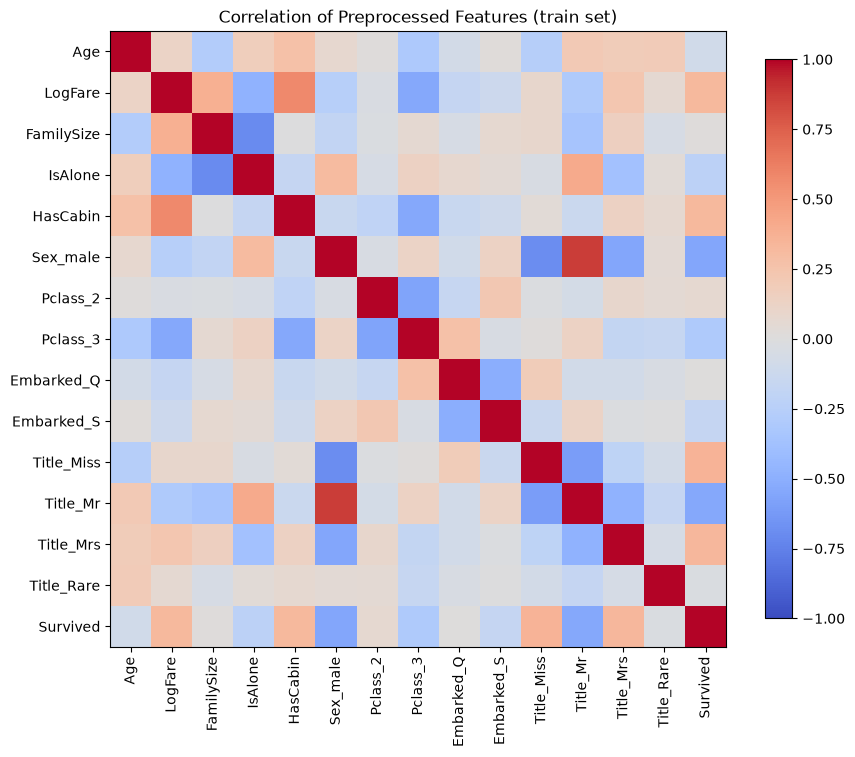

X_train: (713, 14) | y_train: (713,)
X_test:  (178, 14) | y_test:  (178,)

Correlation with Survived:
Sex_male     -0.552
Title_Mr     -0.545
Pclass_3     -0.300
IsAlone      -0.223
Embarked_S   -0.168
Age          -0.088
Title_Rare   -0.029
Embarked_Q    0.004
FamilySize    0.014
Pclass_2      0.066
LogFare       0.321
HasCabin      0.325
Title_Mrs     0.329
Title_Miss    0.356


In [6]:
# Cell 6: Convert to arrays and check feature correlations
X_train = X_train_df.values            # model inputs as plain NumPy arrays
X_test  = X_test_df.values
y_train = train_df["Survived"].values  # targets (0 = died, 1 = survived)
y_test  = test_df["Survived"].values
feature_names = list(X_train_df.columns)

def plot_correlation(X_df, y):
    d = X_df.copy()
    d["Survived"] = y
    corr = d.corr()
    plt.figure(figsize=(9, 8))
    plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    plt.colorbar(shrink=0.8)
    plt.xticks(range(len(corr)), corr.columns, rotation=90)
    plt.yticks(range(len(corr)), corr.columns)
    plt.title("Correlation of Preprocessed Features (train set)")
    plt.tight_layout()
    plt.show()
    return corr["Survived"].drop("Survived").sort_values()

target_corr = plot_correlation(X_train_df, y_train)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test: ", X_test.shape, "| y_test: ", y_test.shape)
print("\nCorrelation with Survived:")
print(target_corr.round(3).to_string())


In [ ]:
# Cell 7: The LogisticRegression class
class LogisticRegression:
    def __init__(self, lr=0.1, n_iters=3000, lam=0.0, tol=1e-9):
        self.lr = lr              # learning rate (step size)
        self.n_iters = n_iters    # maximum number of gradient-descent steps
        self.lam = lam            # L2 regularisation strength (0 = none)
        self.tol = tol            # stop early if the loss barely changes
        self.w = None
        self.b = 0.0
        self.loss_history = []
        self.val_loss_history = []

    @staticmethod
    def sigmoid(z):
        out = np.empty_like(z, dtype=float)
        pos = z >= 0
        out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))      
        ez = np.exp(z[~pos])
        out[~pos] = ez / (1.0 + ez)                   
        return out

    def predict_proba(self, X):
        return self.sigmoid(X @ self.w + self.b)      

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def loss(self, X, y):
        p = np.clip(self.predict_proba(X), 1e-15, 1 - 1e-15)       
        cross_entropy = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
        penalty = self.lam / (2 * len(y)) * np.sum(self.w ** 2)    
        return cross_entropy + penalty

    def gradients(self, X, y):
        m = X.shape[0]
        error = self.predict_proba(X) - y                         
        dw = X.T @ error / m + (self.lam / m) * self.w
        db = error.mean()
        return dw, db

    def fit(self, X, y, X_val=None, y_val=None):
        self.w = np.zeros(X.shape[1])                              
        self.b = 0.0
        self.loss_history, self.val_loss_history = [], []
        for i in range(self.n_iters):
            dw, db = self.gradients(X, y)
            self.w -= self.lr * dw                                
            self.b -= self.lr * db
            self.loss_history.append(self.loss(X, y))
            if X_val is not None:
                self.val_loss_history.append(self.loss(X_val, y_val))
            if i > 0 and abs(self.loss_history[-2] - self.loss_history[-1]) < self.tol:
                break
        self.n_iter_ = len(self.loss_history)
        return self

#Small test to check if the model is learning
model = LogisticRegression(lr=0.1, n_iters=3000, lam=1.0)
model.fit(X_train, y_train)
print("Iterations run:", model.n_iter_)
print("Loss: first = %.4f -> last = %.4f" % (model.loss_history[0], model.loss_history[-1]))
print("Train accuracy: %.3f" % np.mean(model.predict(X_train) == y_train))
print("Weights:", len(model.w), "| bias: %.3f" % model.b)
print("sigmoid(-800, 0, 800) ->", LogisticRegression.sigmoid(np.array([-800., 0., 800.])))


Iterations run: 3000
Loss: first = 0.6763 -> last = 0.4083
Train accuracy: 0.830
Weights: 14 | bias: 1.131
sigmoid(-800, 0, 800) -> [0.  0.5 1. ]


In [8]:
# Cell 8: Evaluation metrics
def confusion_matrix(y, yhat):
    tn = int(np.sum((y == 0) & (yhat == 0)))
    fp = int(np.sum((y == 0) & (yhat == 1)))
    fn = int(np.sum((y == 1) & (yhat == 0)))
    tp = int(np.sum((y == 1) & (yhat == 1)))
    return np.array([[tn, fp], [fn, tp]])

def classification_metrics(y, yhat):
    (tn, fp), (fn, tp) = confusion_matrix(y, yhat)
    accuracy    = (tp + tn) / len(y)
    precision   = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall      = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {"Accuracy": accuracy, "Precision": precision, "Recall": recall,
            "Specificity": specificity, "F1": f1}

def log_loss(y, p):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def roc_curve(y, p):
    order = np.argsort(-p)                            # highest score first
    y_sorted, p_sorted = y[order], p[order]
    last_of_tie = np.r_[np.where(np.diff(p_sorted))[0], len(p_sorted) - 1]
    tps = np.cumsum(y_sorted)[last_of_tie]            # true positives at each threshold
    fps = 1 + last_of_tie - tps                       # false positives at each threshold
    tpr = np.r_[0, tps / tps[-1]]
    fpr = np.r_[0, fps / fps[-1]]
    return fpr, tpr

def auc_score(fpr, tpr):
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))   # trapezoid rule

def evaluate(model, X, y, threshold=0.5):
    p = model.predict_proba(X)
    yhat = (p >= threshold).astype(int)
    out = classification_metrics(y, yhat)
    fpr, tpr = roc_curve(y, p)
    out["ROC-AUC"] = auc_score(fpr, tpr)
    out["Log-loss"] = log_loss(y, p)
    return out

# Try it on the model from Cell 7
print(pd.DataFrame({"Train": evaluate(model, X_train, y_train),
                    "Test":  evaluate(model, X_test, y_test)}).round(4))


              Train    Test
Accuracy     0.8303  0.8146
Precision    0.7909  0.7778
Recall       0.7591  0.7206
Specificity  0.8747  0.8727
F1           0.7747  0.7481
ROC-AUC      0.8817  0.8506
Log-loss     0.4025  0.4553


Fold sizes (validation): [143, 143, 143, 143, 141]
      lr    lam  cv_log_loss  log_loss_sd  cv_accuracy
0   0.50    1.0       0.4174       0.0660       0.8247
1   0.10    1.0       0.4186       0.0662       0.8205
2   0.50    0.1       0.4189       0.0699       0.8275
3   0.05    0.1       0.4192       0.0653       0.8191
4   0.05    0.0       0.4192       0.0655       0.8191
5   0.10    0.1       0.4192       0.0698       0.8233
6   0.50    0.0       0.4193       0.0704       0.8275
7   0.05    1.0       0.4193       0.0630       0.8233
8   0.10    0.0       0.4194       0.0703       0.8233
9   0.50   10.0       0.4265       0.0497       0.8247
10  0.10   10.0       0.4270       0.0496       0.8247
11  0.05   10.0       0.4282       0.0493       0.8233
12  0.01    0.0       0.4367       0.0464       0.8289
13  0.01    0.1       0.4368       0.0463       0.8289
14  0.01    1.0       0.4375       0.0459       0.8289
15  0.01   10.0       0.4451       0.0419       0.8275
16  0.50  100.

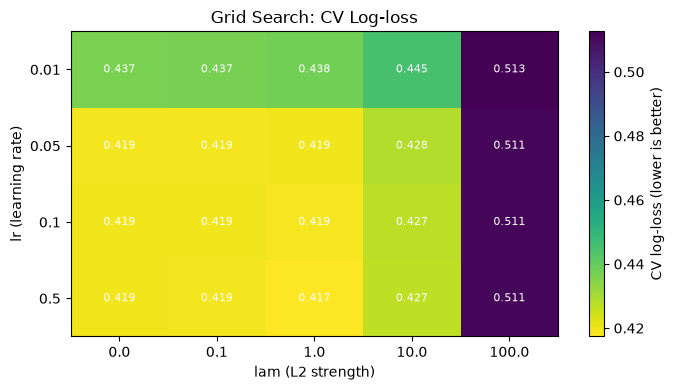

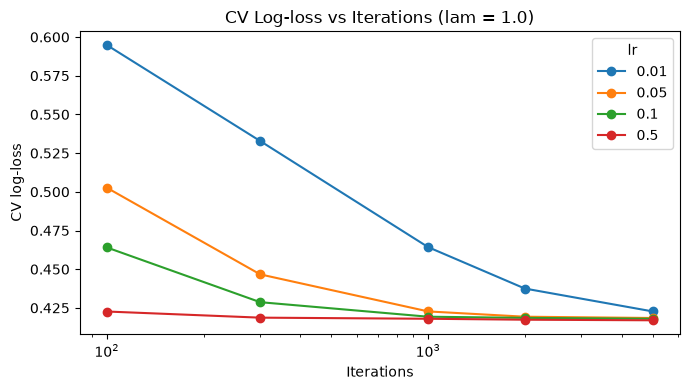

           0.01    0.05    0.10    0.50
n_iters                                
100      0.5948  0.5026  0.4640  0.4227
300      0.5328  0.4467  0.4287  0.4187
1000     0.4642  0.4227  0.4193  0.4180
2000     0.4375  0.4193  0.4186  0.4174
5000     0.4227  0.4185  0.4180  0.4170
               features  CV log-loss  CV accuracy  folds won (lower loss)
With Title           14       0.4174       0.8247                       5
Without Title        10       0.4292       0.8163                       0
Per-fold loss difference (without - with): [0.0071 0.0027 0.0118 0.0215 0.0162]

Keeping Title features: True


In [ ]:
# Cell 9: Cross-validation and grid search (training data only)
def make_folds(df, k=5, seed=12):
    np.random.seed(seed)
    y = df["Survived"].values
    fold_ids = np.zeros(len(df), dtype=int)
    for cls in np.unique(y):                               # stratified: spread each class evenly
        idx = np.random.permutation(np.where(y == cls)[0])
        for f, chunk in enumerate(np.array_split(idx, k)):
            fold_ids[chunk] = f
    folds = []
    for f in range(k):
        tr, va = df[fold_ids != f], df[fold_ids == f]
        p = TitanicPreprocessor().fit(tr)                  # preprocessing learned from this fold's train part only
        folds.append((p.transform(tr), tr["Survived"].values,
                      p.transform(va), va["Survived"].values))
    return folds

def cross_validate(folds, lr, lam, n_iters, cols=None):
    losses, accs = [], []
    for X_tr, y_tr, X_va, y_va in folds:
        if cols is not None:                               # optional: use only some feature columns
            X_tr, X_va = X_tr[cols], X_va[cols]
        m = LogisticRegression(lr=lr, n_iters=n_iters, lam=lam).fit(X_tr.values, y_tr)
        p = m.predict_proba(X_va.values)
        losses.append(log_loss(y_va, p))
        accs.append(np.mean((p >= 0.5) == y_va))
    return np.mean(losses), np.std(losses), np.mean(accs)

folds = make_folds(train_df, k=5, seed=12)
print("Fold sizes (validation):", [len(f[3]) for f in folds])

lr_grid  = [0.01, 0.05, 0.1, 0.5]
lam_grid = [0, 0.1, 1, 10, 100]
N_ITERS  = 2000

rows = []
for lr in lr_grid:
    for lam in lam_grid:
        ll, ll_sd, acc = cross_validate(folds, lr, lam, N_ITERS)
        rows.append({"lr": lr, "lam": lam, "cv_log_loss": ll,
                     "log_loss_sd": ll_sd, "cv_accuracy": acc})

cv_results = pd.DataFrame(rows).sort_values("cv_log_loss").reset_index(drop=True)
print(cv_results.round(4).to_string())

best_lr  = cv_results.loc[0, "lr"]
best_lam = cv_results.loc[0, "lam"]
print("\nBest by CV log-loss: lr =", best_lr, "| lam =", best_lam)


In [ ]:
# Cell 10: Reading the grid search, choosing iterations, and testing Title
#1. Heatmap of the grid search
grid = cv_results.pivot(index="lr", columns="lam", values="cv_log_loss")
plt.figure(figsize=(7, 4))
plt.imshow(grid.values, cmap="viridis_r", aspect="auto")
plt.colorbar(label="CV log-loss (lower is better)")
plt.xticks(range(len(grid.columns)), grid.columns)
plt.yticks(range(len(grid.index)), grid.index)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        plt.text(j, i, "%.3f" % grid.values[i, j], ha="center", va="center",
                 color="white", fontsize=8)
plt.xlabel("lam (L2 strength)")
plt.ylabel("lr (learning rate)")
plt.title("Grid Search: CV Log-loss")
plt.tight_layout()
plt.show()

#2. How many iterations are enough? 
iter_grid = [100, 300, 1000, 2000, 5000]
iter_df = pd.DataFrame(
    {lr: [cross_validate(folds, lr, best_lam, n)[0] for n in iter_grid] for lr in lr_grid},
    index=iter_grid)
iter_df.index.name = "n_iters"
iter_df.plot(marker="o", figsize=(7, 4), title="CV Log-loss vs Iterations (lam = %s)" % best_lam)
plt.xscale("log")
plt.xlabel("Iterations")
plt.ylabel("CV log-loss")
plt.legend(title="lr")
plt.tight_layout()
plt.show()
print(iter_df.round(4).to_string())

chosen_iters = 2000  

# 3. Keep the Title features or not? 
def cv_scores(folds, lr, lam, n_iters, cols):
    losses, accs = [], []
    for X_tr, y_tr, X_va, y_va in folds:
        m = LogisticRegression(lr=lr, n_iters=n_iters, lam=lam).fit(X_tr[cols].values, y_tr)
        p = m.predict_proba(X_va[cols].values)
        losses.append(log_loss(y_va, p))
        accs.append(np.mean((p >= 0.5) == y_va))
    return np.array(losses), np.array(accs)

all_cols = list(X_train_df.columns)
no_title = [c for c in all_cols if not c.startswith("Title_")]
l_with, a_with = cv_scores(folds, best_lr, best_lam, chosen_iters, all_cols)
l_wo,   a_wo   = cv_scores(folds, best_lr, best_lam, chosen_iters, no_title)

compare = pd.DataFrame({
    "features": [len(all_cols), len(no_title)],
    "CV log-loss": [l_with.mean(), l_wo.mean()],
    "CV accuracy": [a_with.mean(), a_wo.mean()],
    "folds won (lower loss)": [int(np.sum(l_with < l_wo)), int(np.sum(l_wo < l_with))],
}, index=["With Title", "Without Title"])
print(compare.round(4).to_string())
print("Per-fold loss difference (without - with):", np.round(l_wo - l_with, 4))

final_cols = all_cols if l_with.mean() < l_wo.mean() else no_title
print("\nKeeping Title features:", final_cols == all_cols)

Trained with lr=0.5, lam=1.0, iterations=2000


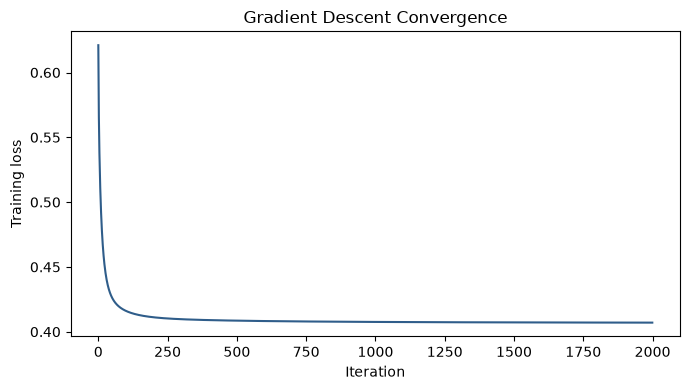

              Train    Test
Accuracy     0.8317  0.8202
Precision    0.7962  0.7903
Recall       0.7555  0.7206
Specificity  0.8793  0.8818
F1           0.7753  0.7538
ROC-AUC      0.8822  0.8515
Log-loss     0.4005  0.4525

Majority-class baseline accuracy (test): 0.6180


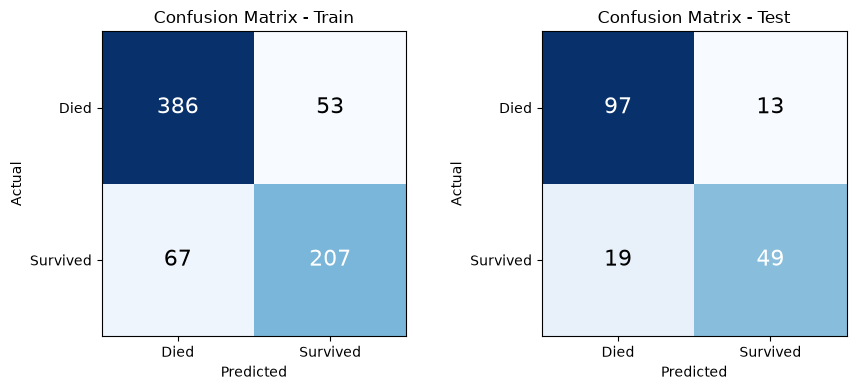

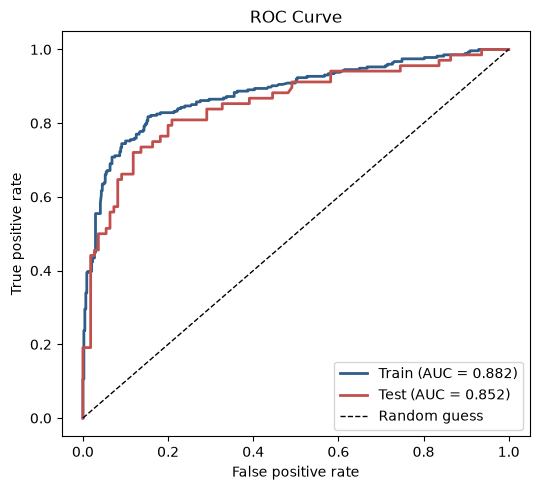

In [10]:
# Cell 11: Final model, training curve, and test-set evaluation
X_tr_final = X_train_df[final_cols].values
X_te_final = X_test_df[final_cols].values

final_model = LogisticRegression(lr=best_lr, n_iters=chosen_iters, lam=best_lam)
final_model.fit(X_tr_final, y_train)
print("Trained with lr=%s, lam=%s, iterations=%d" % (best_lr, best_lam, final_model.n_iter_))

# Loss curve
plt.figure(figsize=(7, 4))
plt.plot(final_model.loss_history, color="#2f5d8a")
plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.title("Gradient Descent Convergence")
plt.tight_layout()
plt.show()

# Metrics
results = pd.DataFrame({"Train": evaluate(final_model, X_tr_final, y_train),
                        "Test":  evaluate(final_model, X_te_final, y_test)})
print(results.round(4).to_string())
baseline = max(y_test.mean(), 1 - y_test.mean())
print("\nMajority-class baseline accuracy (test): %.4f" % baseline)

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, X, y) in zip(axes, [("Train", X_tr_final, y_train), ("Test", X_te_final, y_test)]):
    cm = confusion_matrix(y, final_model.predict(X))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Died", "Survived"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Died", "Survived"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title("Confusion Matrix - " + name)
plt.tight_layout()
plt.show()

# ROC curves
plt.figure(figsize=(5.5, 5))
for name, X, y, c in [("Train", X_tr_final, y_train, "#2f5d8a"), ("Test", X_te_final, y_test, "#c0504d")]:
    fpr, tpr = roc_curve(y, final_model.predict_proba(X))
    plt.plot(fpr, tpr, color=c, lw=2, label="%s (AUC = %.3f)" % (name, auc_score(fpr, tpr)))
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


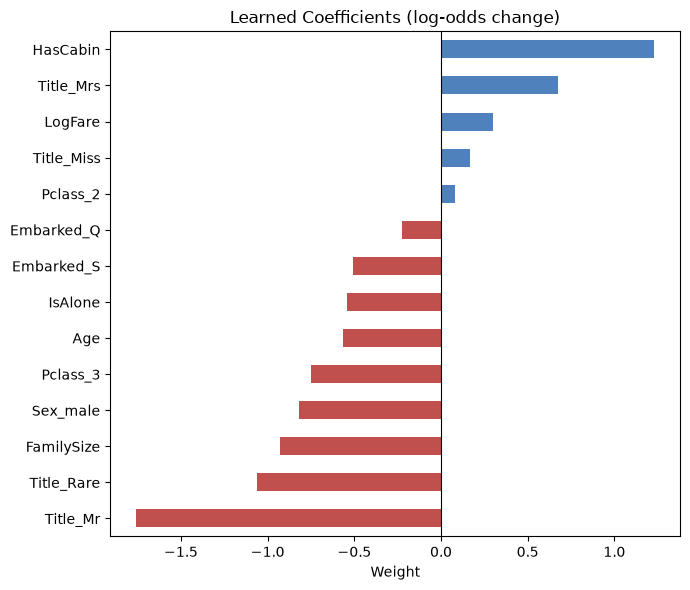

            weight  odds_multiplier
HasCabin     1.229            3.418
Title_Mrs    0.677            1.969
LogFare      0.302            1.353
Title_Miss   0.169            1.184
Pclass_2     0.079            1.082
Embarked_Q  -0.227            0.797
Embarked_S  -0.507            0.602
IsAlone     -0.541            0.582
Age         -0.564            0.569
Pclass_3    -0.749            0.473
Sex_male    -0.820            0.440
FamilySize  -0.928            0.395
Title_Rare  -1.062            0.346
Title_Mr    -1.758            0.172
bias: 1.615


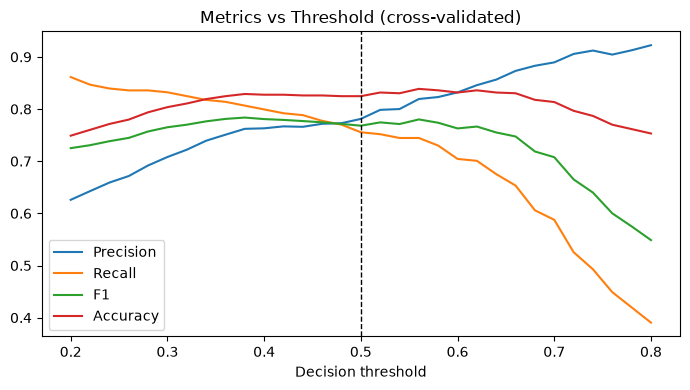

Threshold with best CV F1: 0.38 (F1 = 0.7837; at 0.50 F1 = 0.7681)
             Threshold 0.50  Threshold 0.38
Accuracy             0.8202          0.7978
Precision            0.7903          0.7105
Recall               0.7206          0.7941
Specificity          0.8818          0.8000
F1                   0.7538          0.7500
ROC-AUC              0.8515          0.8515
Log-loss             0.4525          0.4525
[[88 22]
 [14 54]]


In [ ]:
# Cell 12: Coefficients, threshold analysis, and conclusion
# What did the model learn? 
coef = pd.Series(final_model.w, index=final_cols).sort_values()
coef.plot(kind="barh", figsize=(7, 6),
          color=["#4f81bd" if v > 0 else "#c0504d" for v in coef],
          title="Learned Coefficients (log-odds change)")
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Weight")
plt.tight_layout()
plt.show()

odds = pd.DataFrame({"weight": coef, "odds_multiplier": np.exp(coef)}).iloc[::-1]
print(odds.round(3).to_string())
print("bias: %.3f" % final_model.b)

# Threshold analysis on out-of-fold CV predictions
oof_p, oof_y = [], []
for X_tr, y_tr, X_va, y_va in folds:
    m = LogisticRegression(lr=best_lr, n_iters=chosen_iters, lam=best_lam).fit(X_tr[final_cols].values, y_tr)
    oof_p.append(m.predict_proba(X_va[final_cols].values))
    oof_y.append(y_va)
oof_p, oof_y = np.concatenate(oof_p), np.concatenate(oof_y)

thresholds = np.arange(0.20, 0.801, 0.02)
curve = pd.DataFrame([classification_metrics(oof_y, (oof_p >= t).astype(int)) for t in thresholds],
                     index=np.round(thresholds, 2))
curve[["Precision", "Recall", "F1", "Accuracy"]].plot(figsize=(7, 4),
                                                      title="Metrics vs Threshold (cross-validated)")
plt.axvline(0.5, color="black", ls="--", lw=1)
plt.xlabel("Decision threshold")
plt.tight_layout()
plt.show()

best_t = float(curve["F1"].idxmax())
print("Threshold with best CV F1: %.2f (F1 = %.4f; at 0.50 F1 = %.4f)" % (
    best_t, curve["F1"].max(), curve.loc[0.5, "F1"]))

# Test set: default 0.5 vs the CV-chosen threshold
cmp_t = pd.DataFrame({
    "Threshold 0.50": evaluate(final_model, X_te_final, y_test, threshold=0.5),
    "Threshold %.2f" % best_t: evaluate(final_model, X_te_final, y_test, threshold=best_t)})
print(cmp_t.round(4).to_string())
print(confusion_matrix(y_test, final_model.predict(X_te_final, threshold=best_t)))